# 01 — UNSW-NB15 exploratory data analysis
CyberSOC · Milestone I. Size, structure, class balance and data quality of the dataset feeding the network/anomaly agents.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path('..') / 'src'))
import pandas as pd
from cybersoc.detection.eda import load, summarize, plots
train, test = load(pathlib.Path('../data/raw'))
train.shape, test.shape

((175341, 45), (82332, 45))

## Structure

In [2]:
train.dtypes.value_counts()

int64      30
float64    11
str         4
Name: count, dtype: int64

In [3]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


## Class balance
Note the label split differs between train (68% attack) and test (55% attack), and Worms has only 130 training records.

In [4]:
pd.concat({'train': train['attack_cat'].value_counts(), 'test': test['attack_cat'].value_counts()}, axis=1)

,train,test
attack_cat,,
Normal,56000,37000
Generic,40000,18871
Exploits,33393,11132
Fuzzers,18184,6062
DoS,12264,4089
Reconnaissance,10491,3496
Analysis,2000,677
Backdoor,1746,583
Shellcode,1133,378


## Data quality

In [5]:
s = summarize(train, test)
{k: s['train'][k] for k in ['missing_cells','duplicate_rows_excl_id','service_dash_share','infinite_values']}

{'missing_cells': 0,
 'duplicate_rows_excl_id': 67601,
 'service_dash_share': 0.5371,
 'infinite_values': 0}

In [6]:
s['redundant_pairs_gt_0_95']

[('spkts', 'sbytes', 0.964),
 ('spkts', 'sloss', 0.971),
 ('dpkts', 'dbytes', 0.972),
 ('dpkts', 'dloss', 0.979),
 ('sbytes', 'sloss', 0.996),
 ('dbytes', 'dloss', 0.997),
 ('swin', 'dwin', 0.99),
 ('ct_srv_src', 'ct_dst_src_ltm', 0.967),
 ('ct_srv_src', 'ct_srv_dst', 0.98),
 ('ct_dst_ltm', 'ct_src_dport_ltm', 0.962),
 ('ct_dst_src_ltm', 'ct_srv_dst', 0.972),
 ('is_ftp_login', 'ct_ftp_cmd', 1.0)]

## Figures

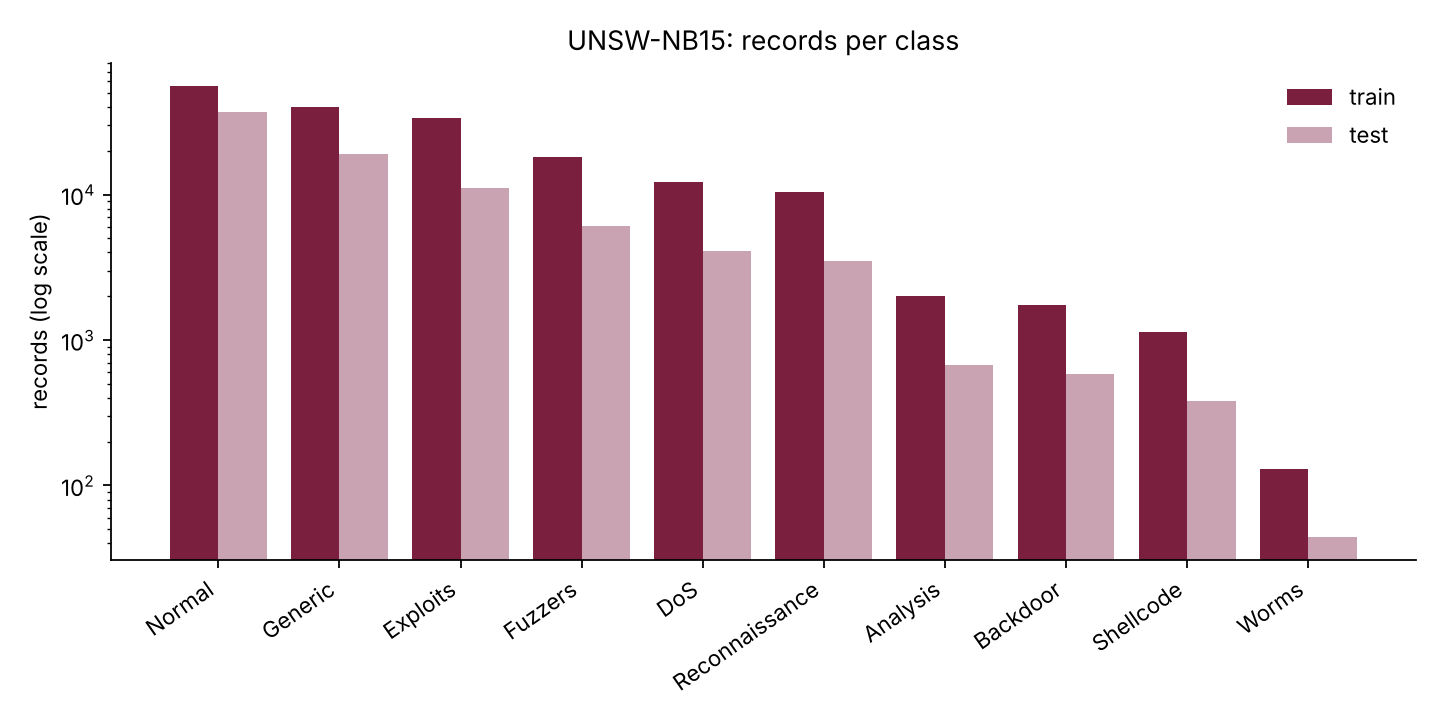

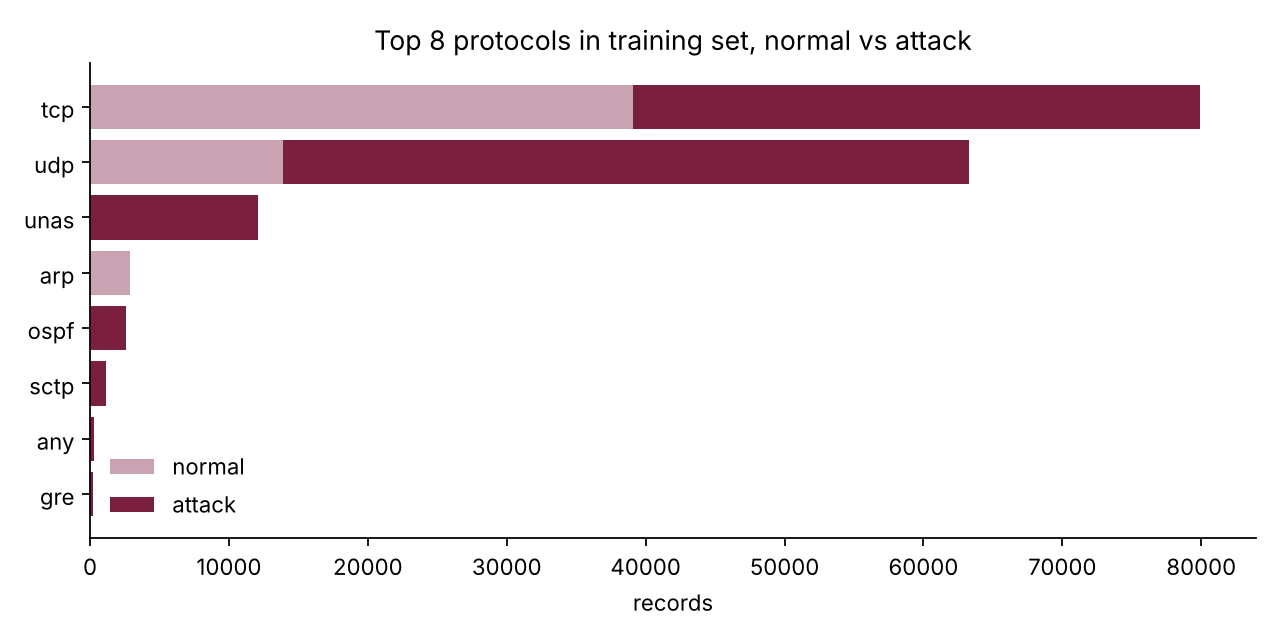

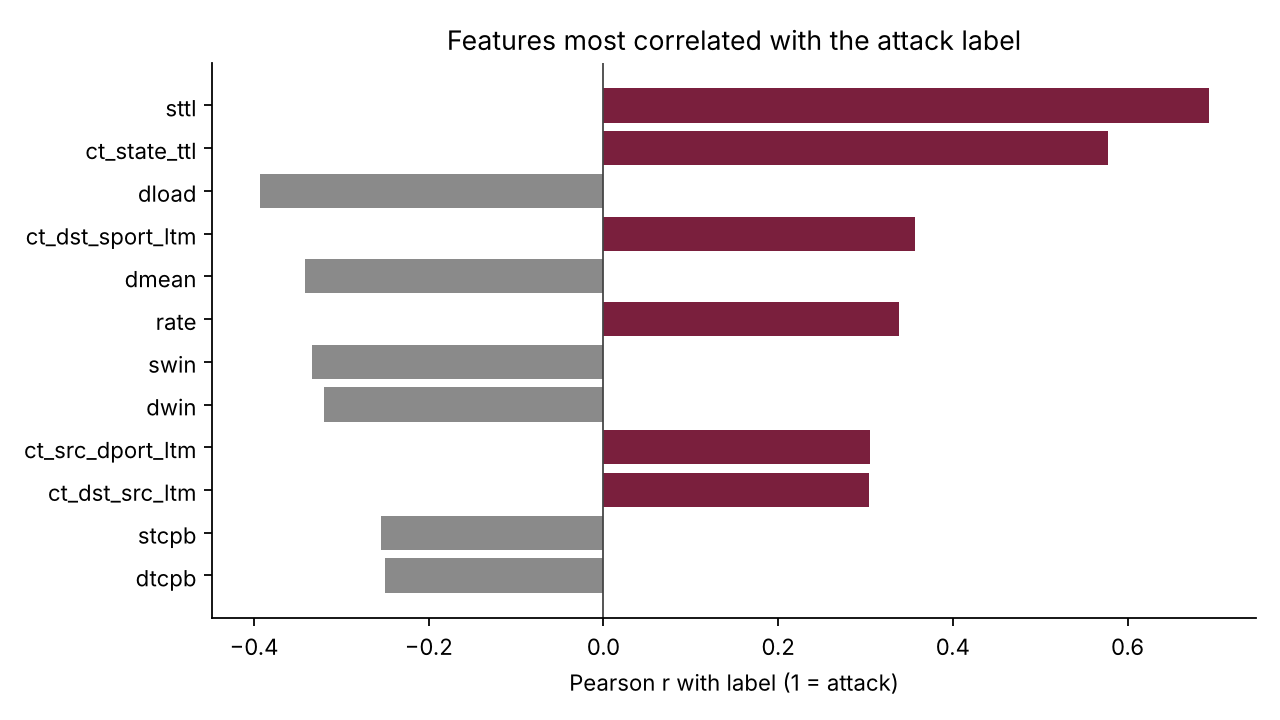

In [7]:
plots(train, test, pathlib.Path('../reports/figures'))
from IPython.display import Image, display
for f in ['class_distribution','protocols','label_correlation']:
    display(Image(f'../reports/figures/{f}.png'))

## Takeaways for the design
- ~39% of training rows are exact duplicates once `id` is dropped → deduplicate before cross-validation to avoid leakage.
- 12 near-identical feature pairs (|r| > 0.95) → prune for the DL models.
- Severe imbalance in rare classes → class weights / resampling; report macro-F1, not just accuracy.
- `service` is unknown ('-') for over half the flows → the investigation agent cannot rely on it.